In [69]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

import warnings
warnings.filterwarnings('ignore')

In [70]:
df = pd.read_csv("../Dataset/dataset_phishing.csv")
df.head()

,url,length_url,length_hostname,ip,nb_dots,nb_hyphens,nb_at,nb_qm,nb_and,nb_or,...,domain_in_title,domain_with_copyright,whois_registered_domain,domain_registration_length,domain_age,web_traffic,dns_record,google_index,page_rank,status
0,http://www.crestonwood.com/router.php,37,19,0,3,0,0,0,0,0,...,0,1,0,45,-1,0,1,1,4,legitimate
1,http://shadetreetechnology.com/V4/validation/a...,77,23,1,1,0,0,0,0,0,...,1,0,0,77,5767,0,0,1,2,phishing
2,https://support-appleld.com.secureupdate.duila...,126,50,1,4,1,0,1,2,0,...,1,0,0,14,4004,5828815,0,1,0,phishing
3,http://rgipt.ac.in,18,11,0,2,0,0,0,0,0,...,1,0,0,62,-1,107721,0,0,3,legitimate
4,http://www.iracing.com/tracks/gateway-motorspo...,55,15,0,2,2,0,0,0,0,...,0,1,0,224,8175,8725,0,0,6,legitimate


In [71]:
df.shape

(11430, 89)

In [72]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11430 entries, 0 to 11429
Data columns (total 89 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   url                         11430 non-null  object 
 1   length_url                  11430 non-null  int64  
 2   length_hostname             11430 non-null  int64  
 3   ip                          11430 non-null  int64  
 4   nb_dots                     11430 non-null  int64  
 5   nb_hyphens                  11430 non-null  int64  
 6   nb_at                       11430 non-null  int64  
 7   nb_qm                       11430 non-null  int64  
 8   nb_and                      11430 non-null  int64  
 9   nb_or                       11430 non-null  int64  
 10  nb_eq                       11430 non-null  int64  
 11  nb_underscore               11430 non-null  int64  
 12  nb_tilde                    11430 non-null  int64  
 13  nb_percent                  114

In [73]:
df.isnull().sum()

url                0
length_url         0
length_hostname    0
ip                 0
nb_dots            0
                  ..
web_traffic        0
dns_record         0
google_index       0
page_rank          0
status             0
Length: 89, dtype: int64

In [74]:
df.describe()

,length_url,length_hostname,ip,nb_dots,nb_hyphens,nb_at,nb_qm,nb_and,nb_or,nb_eq,...,empty_title,domain_in_title,domain_with_copyright,whois_registered_domain,domain_registration_length,domain_age,web_traffic,dns_record,google_index,page_rank
count,11430.000000,11430.000000,11430.000000,11430.000000,11430.000000,11430.000000,11430.000000,11430.000000,11430.0,11430.000000,...,11430.000000,11430.000000,11430.000000,11430.000000,11430.000000,11430.000000,1.143000e+04,11430.000000,11430.000000,11430.000000
mean,61.126684,21.090289,0.150569,2.480752,0.997550,0.022222,0.141207,0.162292,0.0,0.293176,...,0.124759,0.775853,0.439545,0.072878,492.532196,4062.543745,8.567566e+05,0.020122,0.533946,3.185739
std,55.297318,10.777171,0.357644,1.369686,2.087087,0.155500,0.364456,0.821337,0.0,0.998317,...,0.330460,0.417038,0.496353,0.259948,814.769415,3107.784600,1.995606e+06,0.140425,0.498868,2.536955
min,12.000000,4.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,...,0.000000,0.000000,0.000000,0.000000,-1.000000,-12.000000,0.000000e+00,0.000000,0.000000,0.000000
25%,33.000000,15.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,...,0.000000,1.000000,0.000000,0.000000,84.000000,972.250000,0.000000e+00,0.000000,0.000000,1.000000
50%,47.000000,19.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,...,0.000000,1.000000,0.000000,0.000000,242.000000,3993.000000,1.651000e+03,0.000000,1.000000,3.000000
75%,71.000000,24.000000,0.000000,3.000000,1.000000,0.000000,0.000000,0.000000,0.0,0.000000,...,0.000000,1.000000,1.000000,0.000000,449.000000,7026.750000,3.738455e+05,0.000000,1.000000,5.000000
max,1641.000000,214.000000,1.000000,24.000000,43.000000,4.000000,3.000000,19.000000,0.0,19.000000,...,1.000000,1.000000,1.000000,1.000000,29829.000000,12874.000000,1.076799e+07,1.000000,1.000000,10.000000


In [75]:
df['status'].value_counts()

status
legitimate    5715
phishing      5715
Name: count, dtype: int64

In [76]:
print(f"Phishing: {(df['status'] == 'phishing').mean():.0%}")

Phishing: 50%


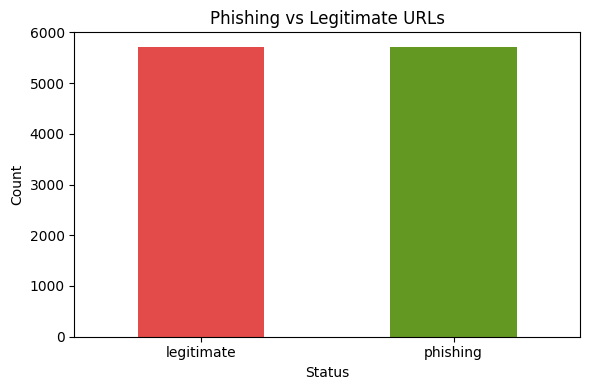

In [77]:
plt.figure(figsize=(6,4))

df['status'].value_counts().plot(kind='bar', color=['#E24B4A','#639922'])
plt.title('Phishing vs Legitimate URLs')
plt.xlabel('Status')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [78]:
df['label'] = (df['status'] == 'phishing').astype(int)
df[['status', 'label']].value_counts()

status      label
legitimate  0        5715
phishing    1        5715
Name: count, dtype: int64

In [79]:
X = df.drop(['status', 'label', 'url'], axis=1, errors='ignore')
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

model = RandomForestClassifier(n_estimators=100, max_depth=15, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",15
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y

In [80]:
y_pred = model.predict(X_test)
y_pred

array([1, 1, 1, ..., 0, 0, 0], shape=(2286,))

In [81]:
acc = accuracy_score(y_test, y_pred)*100
acc

96.19422572178478

In [82]:
print(classification_report(y_test, y_pred, target_names=['Legitimate','Phishing']))

              precision    recall  f1-score   support

  Legitimate       0.97      0.96      0.96      1143
    Phishing       0.96      0.97      0.96      1143

    accuracy                           0.96      2286
   macro avg       0.96      0.96      0.96      2286
weighted avg       0.96      0.96      0.96      2286



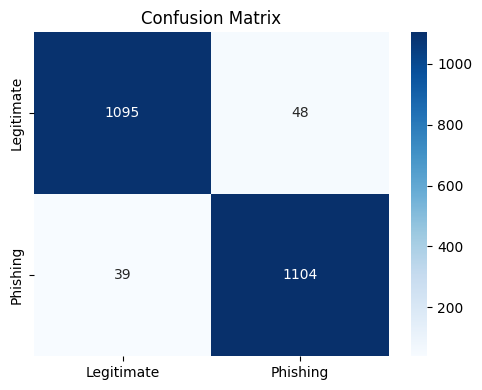

In [83]:
plt.figure(figsize=(5,4))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Legitimate','Phishing'], yticklabels=['Legitimate','Phishing'])
plt.title('Confusion Matrix')
plt.tight_layout(); plt.show()

AUC: 0.9927


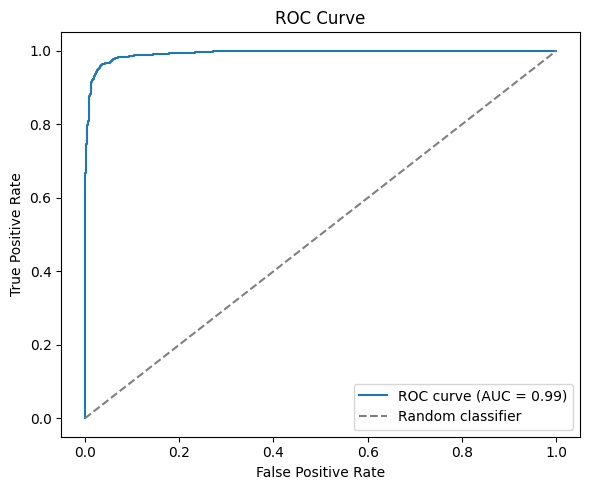

In [84]:
from sklearn.metrics import roc_curve, auc


y_score = model.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_score)

roc_auc = auc(fpr, tpr)

print(f'AUC: {roc_auc:.4f}')


plt.figure(figsize=(6, 5))

plt.plot(fpr, tpr, label=f'ROC curve (AUC = {roc_auc:.2f})')

plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random classifier')

plt.xlabel('False Positive Rate')

plt.ylabel('True Positive Rate')

plt.title('ROC Curve')

plt.legend(loc='lower right')

plt.tight_layout()

plt.show()

In [85]:
from sklearn.metrics import roc_curve, auc

y_score = model.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_score)

roc_auc = auc(fpr, tpr)
roc_auc 

0.9927276150848598

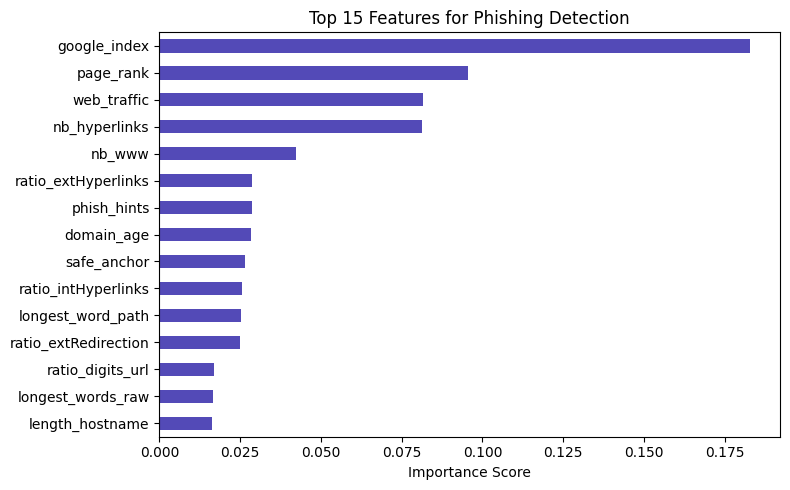

In [86]:
plt.figure(figsize=(8,5))

importances = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False).head(15)
importances.plot(kind='barh', color='#534AB7')
plt.title('Top 15 Features for Phishing Detection')
plt.xlabel('Importance Score')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [ ]:
import pickle, json

with open('phishing_model.pkl', 'wb') as f: pickle.dump(model, f)

feature_info = {
    'features': X.columns.tolist(),
    'accuracy': float(acc),
    'model_type': 'RandomForestClassifier',
    'dataset': 'Web Page Phishing Detection (Kaggle)',
    'samples_trained': int(len(X_train))
}

with open('model_info.json', 'w') as f: json.dump(feature_info, f, indent=2)

print("Model saved! Files:")

Model saved! Files:
 - phishing_model.pkl (7651 KB)
 - model_info.json (2 KB)


In [88]:
import os
for f in ['phishing_model.pkl','model_info.json']:
    print(f" - {f} ({os.path.getsize(f)/1024:.0f} KB)")

 - phishing_model.pkl (7651 KB)
 - model_info.json (2 KB)


In [90]:
def predict_url(url_features: dict):
    """
    Pass a dict of feature values to get a prediction.
    """
    import pandas as pd
    sample = pd.DataFrame([url_features])
    sample = sample.reindex(columns=X.columns, fill_value=0)
    pred = model.predict(sample)[0]
    prob = model.predict_proba(sample)[0][1]
    
    label = "PHISHING" if pred == 1 else "LEGITIMATE"
    print(f"Verdict:    {label}")
    print(f"Risk Score: {prob*100:.1f}%")
    return label, prob

# --- Test it with a sample from your dataset ---
print("=== Testing on known PHISHING sample ===")
phishing_sample = X_test[y_test == 1].iloc[0].to_dict()
predict_url(phishing_sample)

print()
print("=== Testing on known LEGITIMATE sample ===")
legit_sample = X_test[y_test == 0].iloc[0].to_dict()
predict_url(legit_sample)

=== Testing on known PHISHING sample ===
Verdict:    PHISHING
Risk Score: 95.9%

=== Testing on known LEGITIMATE sample ===
Verdict:    LEGITIMATE
Risk Score: 1.4%


('LEGITIMATE', np.float64(0.014324690778068494))

In [92]:
print("=" * 45)
print("   CYBERGUARD AI — PHISHING DETECTOR")
print("=" * 45)
print(f"  Dataset     : Web Page Phishing (Kaggle)")
print(f"  Model       : Random Forest (100 trees)")
print(f"  Trained on  : {len(X_train):,} samples")
print(f"  Tested on   : {len(X_test):,} samples")
print(f"  Accuracy    : {acc:.2f}%")
print("=" * 45)
print("  Model file  : phishing_model.pkl")
print("  Info file   : model_info.json")
print("=" * 45)

   CYBERGUARD AI — PHISHING DETECTOR
  Dataset     : Web Page Phishing (Kaggle)
  Model       : Random Forest (100 trees)
  Trained on  : 9,144 samples
  Tested on   : 2,286 samples
  Accuracy    : 96.19%
  Model file  : phishing_model.pkl
  Info file   : model_info.json


In [93]:
import joblib

# Assuming your model variable is called `model`
joblib.dump(model, "phishing_model.pkl")
print("Model saved successfully!")

Model saved successfully!


In [94]:
import joblib

# Assuming your training features are in X
joblib.dump(X.columns, "model_columns.pkl")
print("Columns saved successfully!")

Columns saved successfully!


In [95]:
print("=" * 48)
print("    CYBERGUARD AI — PROJECT SUMMARY")
print("=" * 48)
print(f"  Dataset     : Kaggle Phishing URLs")
print(f"  Total URLs  : {len(df):,}")
print(f"  Features    : {X.shape[1]}")
print(f"  Algorithm   : Random Forest (100 trees)")
print(f"  Train set   : {len(X_train):,} samples (80%)")
print(f"  Test set    : {len(X_test):,} samples (20%)")
print(f"  Accuracy    : {acc*100:.2f}%")
print(f"  Model file  : phishing_model.pkl")
print("=" * 48)
print("  Web App     : CyberGuard_AI_App.html")
print("  AI Engine   : Claude AI (Anthropic)")
print("=" * 48)

    CYBERGUARD AI — PROJECT SUMMARY
  Dataset     : Kaggle Phishing URLs
  Total URLs  : 11,430
  Features    : 87
  Algorithm   : Random Forest (100 trees)
  Train set   : 9,144 samples (80%)
  Test set    : 2,286 samples (20%)
  Accuracy    : 9619.42%
  Model file  : phishing_model.pkl
  Web App     : CyberGuard_AI_App.html
  AI Engine   : Claude AI (Anthropic)
